# **SMS SPAM DETECTION USING LOGISTIC REGRESSION**

AI101-DS Mini Project

In this project we train a Logistic Regression model that looks at a text message (SMS) and decides if it is

- Ham (0): a normal message, or
- Spam (1): an unwanted promo or scam message.

Dataset: SMS Spam Collection from the UCI Machine Learning Repository (5,574 messages, CC BY 4.0).
Almeida, T. & Hidalgo, J. (2011). *SMS Spam Collection* [Dataset]. https://doi.org/10.24432/C5CC84

### 1.1 Import Libraries

First we import all the libraries we need.

In [3]:
# libraries we need for this project
import warnings
import pandas as pd                      # Read and work with tabular data
import numpy as np                       # Numerical operations
import matplotlib.pyplot as plt          # Graphs
import seaborn as sns                    # Heatmaps

# scikit-learn tools: splitting, scaling, text features, feature selection, the model and the metrics
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    log_loss
)

warnings.filterwarnings("ignore")        # hides warning messages in the loop later

%matplotlib inline

# quick check that the imports worked
print("Libraries imported successfully!")

Libraries imported successfully!


### 1.2 Read Dataset

The original file is tab-separated, so we converted it to a CSV file with two columns: `label` and `message`.

In [4]:
# https://archive.ics.uci.edu/dataset/228/sms+spam+collection

# load the CSV (relative path, so it works from the repo folder)
df = pd.read_csv('data/sms_spam.csv')

# shape = (number of rows, number of columns)
print("Dataset shape (rows, columns):", df.shape)

# show the first 5 rows
df.head()

Dataset shape (rows, columns): (5574, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


### 1.3 Understand the Dataset

In [5]:
# column names, data types and how many values are filled in
df.info()

# check for empty values
print("\nMissing values in each column:")
print(df.isnull().sum())

# check for rows that appear more than once
print("\nNumber of duplicate rows:", df.duplicated().sum())

# how many messages are ham and how many are spam
print("\nNumber of ham and spam messages:")
print(df["label"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5574 non-null   str  
 1   message  5574 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB

Missing values in each column:
label      0
message    0
dtype: int64

Number of duplicate rows: 403

Number of ham and spam messages:
label
ham     4827
spam     747
Name: count, dtype: int64


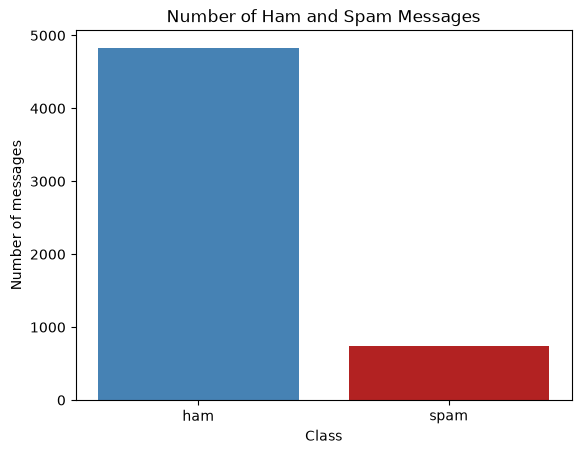

In [6]:
# count the messages in each class and draw a bar chart
counts = df["label"].value_counts()

plt.bar(counts.index, counts.values, color=["steelblue", "firebrick"])
plt.title("Number of Ham and Spam Messages")
plt.xlabel("Class")
plt.ylabel("Number of messages")
plt.show()

Only about 13% of the messages are spam, so the data is imbalanced. A model that says "ham" every single time would already be about 87% accurate, so accuracy alone can fool us. That is why we also look at precision, recall and F1-score later.

The data also has 403 duplicate messages. We remove them before splitting. If we didn't, the same message could end up in both the train and test sets and make the results look better than they really are.

### 1.4 Data Preprocessing

Three things happen here: we drop the duplicate rows, change the label into numbers (ham = 0, spam = 1), and make four numeric features from each message. These are its length, the number of digits, the ratio of capital letters and the number of exclamation marks.

In [7]:
# Steps 1 and 2
# drop_duplicates() removes repeated messages, reset_index() fixes the row numbers
df = df.drop_duplicates().reset_index(drop=True)
# turn the text label into a number: ham = 0, spam = 1
df["spam"] = df["label"].map({"ham": 0, "spam": 1})

# check that the row count and class counts look right
print("Rows after removing duplicates:", len(df))
print(df["spam"].value_counts())

Rows after removing duplicates: 5171
spam
0    4518
1     653
Name: count, dtype: int64


In [8]:
# Step 3: numeric features

# length of the message
df["msg_len"] = df["message"].str.len()

# number of digits: count each digit from 0 to 9 and add them up
df["digit_count"] = 0
for d in "0123456789":
    df["digit_count"] = df["digit_count"] + df["message"].str.count(d)

# number of capital letters: count each capital letter from A to Z and add them up
df["capital_count"] = 0
for letter in "ABCDEFGHIJKLMNOPQRSTUVWXYZ":
    df["capital_count"] = df["capital_count"] + df["message"].str.count(letter)

# ratio of capital letters = capital letters / total length
df["capital_ratio"] = df["capital_count"] / df["msg_len"]

# number of exclamation marks
df["exclaim_count"] = df["message"].str.count("!")

# list of the numeric columns so we can reuse it later
num_cols = ["msg_len", "digit_count", "capital_ratio", "exclaim_count"]

# have a look at the new features
df[["message"] + num_cols].head()

,message,msg_len,digit_count,capital_ratio,exclaim_count
0,"Go until jurong point, crazy.. Available only ...",111,0,0.027027,0
1,Ok lar... Joking wif u oni...,29,0,0.068966,0
2,Free entry in 2 a wkly comp to win FA Cup fina...,155,25,0.064516,0
3,U dun say so early hor... U c already then say...,49,0,0.040816,0
4,"Nah I don't think he goes to usf, he lives aro...",61,0,0.032787,0


`str.count("5")` counts how many times 5 shows up in each message. We do that for every digit from 0 to 9 and add the counts to get the total number of digits. Capital letters are counted the same way.

We picked these features because spam usually has phone numbers, prize codes and lots of exclamation marks. We didn't lowercase or clean the text ourselves, because CountVectorizer does that in section 1.8.

### 1.5 Correlation

Correlation goes from -1 to +1. A value close to +1 means that when the feature goes up, the message is more likely to be spam.

       msg_len  digit_count  capital_ratio  exclaim_count
label                                                    
ham      70.89         0.30           0.06           0.18
spam    137.71        15.49           0.11           0.70


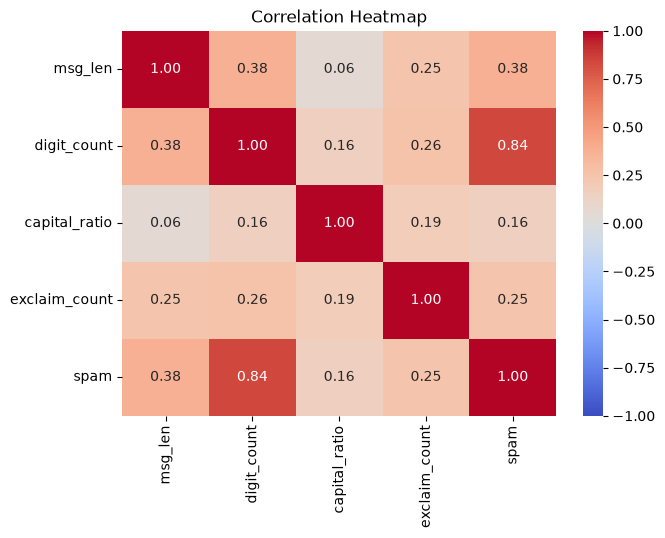

In [9]:
# average of each numeric feature for ham and for spam
print(df.groupby("label")[num_cols].mean().round(2))

# correlation of every feature with each other and with the spam label
corr = df[num_cols + ["spam"]].corr()

plt.figure(figsize=(7, 5))
# coolwarm colours: red = positive, blue = negative
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

`digit_count` has the highest correlation with spam (0.84). Spam messages have about 15 digits on average and ham only about 0.3, because spam contains phone numbers and prize codes. `msg_len` (0.38) and `exclaim_count` (0.25) are weaker but still positive, and `capital_ratio` (0.16) is quite weak. All four are positive, so we kept all of them.

### 1.6 Features, Target and Train-Test Split

X is the message text plus the four numeric features, and y is `spam` (0 or 1). We use 80% of the data for training and 20% for testing. `stratify=y` makes sure both parts have the same share of spam.

In [10]:
# X = the inputs (message text + numeric features), y = what we want to predict
X = df[["message"] + num_cols]
y = df["spam"]

# 80% train, 20% test; random_state=42 keeps the split the same every run
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# check the size of both parts
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (4136, 5)
X_test shape: (1035, 5)


### 1.7 Feature Scaling (Normalization)

The numeric features are on very different scales (`msg_len` can go above 100, while `capital_ratio` is always below 1), so we scale them with StandardScaler. It is fitted on the training data only.

In [11]:
# StandardScaler gives every feature a mean of 0 and a standard deviation of 1
scaler = StandardScaler()

# fit on the training data only, then use the same scaler on the test data
X_train_num = scaler.fit_transform(X_train[num_cols])
X_test_num = scaler.transform(X_test[num_cols])

print("Scaled numeric training data shape:", X_train_num.shape)

Scaled numeric training data shape: (4136, 4)


### 1.8 Convert Text into Numbers (Bag of Words)

The model can't read words, so we use CountVectorizer. It makes the text lowercase, splits it into words, and turns every word from the training messages into a column. The value in the column is how many times that word appears in the message. `min_df=2` ignores words that appear in only one message.

In [12]:
# min_df=2: ignore words that appear in fewer than 2 messages
vectorizer = CountVectorizer(min_df=2)

# fit_transform on train learns the words, transform on test reuses them
X_train_words = vectorizer.fit_transform(X_train["message"])
X_test_words = vectorizer.transform(X_test["message"])

print("Number of words (columns):", X_train_words.shape[1])

Number of words (columns): 3310


`fit_transform()` learns the word list from the training messages and converts them. `transform()` then converts the test messages using that same word list, so nothing from the test set leaks into training.

### 1.9 Feature Selection (Chi-Square)

We have thousands of word columns and many of them don't help. The chi-square test gives each word a score for how strongly it is linked to spam or ham, and `SelectKBest` keeps the best k = 1000 words. Again, only the training data is used.

In [13]:
# keep the 1000 words with the highest chi-square score
selector = SelectKBest(chi2, k=1000)

# the scores are learned from the training data only
X_train_sel = selector.fit_transform(X_train_words, y_train)
X_test_sel = selector.transform(X_test_words)

print("Words before selection:", X_train_words.shape[1])
print("Words after selection :", X_train_sel.shape[1])

Words before selection: 3310
Words after selection : 1000


### 1.10 Combine the Features

Now we put the 1000 selected words and the 4 scaled numeric features side by side in one table.

In [14]:
# hstack puts the columns side by side (.toarray() turns the sparse word table into a normal array)
X_train_final = np.hstack([X_train_sel.toarray(), X_train_num])
X_test_final = np.hstack([X_test_sel.toarray(), X_test_num])

# check the final shapes
print("Final training data shape:", X_train_final.shape)
print("Final testing data shape:", X_test_final.shape)

Final training data shape: (4136, 1004)
Final testing data shape: (1035, 1004)


### 1.11 Training and Testing Functions

`train_model()` makes a Logistic Regression model and trains it with `fit()`. `test_model()` predicts with `predict()` and prints accuracy, precision, recall and F1-score. We use `class_weight="balanced"` so the model pays more attention to spam, since spam is the smaller class.

In [15]:
def train_model(X_train, y_train, max_iter=100):
    # max_iter = the maximum number of solver steps the model may take
    model = LogisticRegression(max_iter=max_iter, class_weight="balanced")
    # fit() learns the coefficients from the training data
    model.fit(X_train, y_train)
    return model


def test_model(model, X, y_true, name):
    # predict() gives 0 (ham) or 1 (spam) for every message
    y_pred = model.predict(X)

    # spam is the positive class, so these scores are for spam
    print("Results on the", name, "data")
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred), 4))
    print("Recall   :", round(recall_score(y_true, y_pred), 4))
    print("F1-score :", round(f1_score(y_true, y_pred), 4))
    print()
    # return the predictions so we can reuse them for the confusion matrix
    return y_pred

### 1.12 Train the Model

In [16]:
# train on the training data only
model = train_model(X_train_final, y_train)

print("Logistic Regression model trained successfully!")
# n_iter_ = how many iterations the solver really used before it stopped
print("Iterations used:", model.n_iter_[0])

Logistic Regression model trained successfully!
Iterations used: 28


### 1.13 Training Plot: Loss vs Iterations

While it trains, the model keeps adjusting its coefficients to lower the log loss, which measures how wrong its predicted probabilities are. To see this happening, we train a fresh model for each `max_iter` from 1 to 30 and plot the loss, a bit like the loop over K in KNN. The test loss is only plotted so we can look at it. It is never used to change the model.

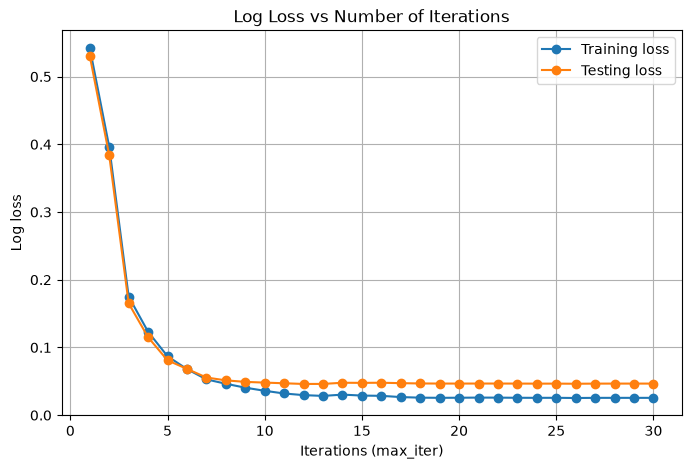

In [17]:
# these lists store the loss for every value of max_iter
train_loss = []
test_loss = []

# train a new model with max_iter = 1, 2, ... 30
for i in range(1, 31):
    temp_model = train_model(X_train_final, y_train, max_iter=i)
    # log_loss needs probabilities, so we use predict_proba
    train_loss.append(log_loss(y_train, temp_model.predict_proba(X_train_final)))
    test_loss.append(log_loss(y_test, temp_model.predict_proba(X_test_final)))

# plot both curves together so we can compare them
plt.figure(figsize=(8, 5))
plt.plot(range(1, 31), train_loss, marker="o", label="Training loss")
plt.plot(range(1, 31), test_loss, marker="o", label="Testing loss")
plt.title("Log Loss vs Number of Iterations")
plt.xlabel("Iterations (max_iter)")
plt.ylabel("Log loss")
plt.legend()
plt.grid(True)
plt.show()

The loss falls fast in the first 5 iterations (training loss 0.54 at iteration 1 and 0.09 at iteration 5) and then flattens out after about 10. In section 1.12 the solver stopped by itself at 28 iterations, so the model has converged.

At the end the training loss (0.026) is lower than the test loss (0.047). The test loss stays flat after about iteration 10 while the training loss keeps going down a little, so there is a small amount of overfitting, but both losses are low.

One thing to remember: LogisticRegression uses the lbfgs solver, so the x-axis is solver iterations and not epochs. The idea is the same though, the loss goes down as the model learns.

### 1.14 Evaluate the Model

Spam (1) is the positive class here. Precision tells us how many of the messages we flagged as spam really were spam. Recall tells us how much of the real spam we caught. F1-score combines the two.

In [18]:
# check the model on the training data and on the unseen test data
y_pred_train = test_model(model, X_train_final, y_train, "training")
y_pred = test_model(model, X_test_final, y_test, "testing")

Results on the training data
Accuracy : 0.9956
Precision: 0.9755
Recall   : 0.9904
F1-score : 0.9829

Results on the testing data
Accuracy : 0.9894
Precision: 0.9762
Recall   : 0.9389
F1-score : 0.9572



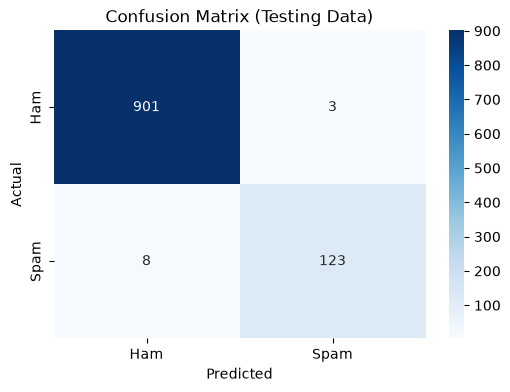

              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       904
        Spam       0.98      0.94      0.96       131

    accuracy                           0.99      1035
   macro avg       0.98      0.97      0.98      1035
weighted avg       0.99      0.99      0.99      1035



In [19]:
# rows = actual class, columns = predicted class
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
# annot=True writes the counts inside the boxes
sns.heatmap(cm, annot=True, cmap="Blues", fmt="d",
            xticklabels=["Ham", "Spam"], yticklabels=["Ham", "Spam"])
plt.title("Confusion Matrix (Testing Data)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# table with precision, recall and F1-score for both classes
print(classification_report(y_test, y_pred, target_names=["Ham", "Spam"]))

On the test data (1,035 messages, 131 of them spam) the confusion matrix gives TN = 901, FP = 3, FN = 8 and TP = 123.

Accuracy is 98.9%, but a model that always says ham would already get 87.3%, so the spam class matters more. Precision is 0.976: we predicted 126 messages as spam and 123 of them really were. Recall is 0.939: there were 131 real spam messages, we found 123 and missed 8. F1-score is 0.957.

Training F1 (0.983) is a bit higher than test F1 (0.957). The gap is small, so the model is slightly better on messages it has already seen, but the test results are still strong.

For a spam filter, sending a real message to spam (false positive) is usually worse than letting a spam message through (false negative). We only have 3 false positives. RMSE is used for regression, where we predict numbers, so it doesn't apply to this classification problem.

We also tried the model without `class_weight="balanced"`. Recall dropped from 0.939 to 0.908 and precision went up from 0.976 to 0.992. F1-score dropped from 0.957 to 0.948, and accuracy barely changed (98.9% to 98.7%). So the setting helps a little, and accuracy alone would have hidden that.

### 1.15 Interpretation

The coefficients show which features push a message towards spam (positive) or towards ham (negative).

In [20]:
# names of the 1000 selected words (get_support() marks the columns we kept) plus the 4 numeric features
feature_names = list(vectorizer.get_feature_names_out()[selector.get_support()]) + num_cols
# coefficient of every feature, sorted from lowest to highest
coef = pd.Series(model.coef_[0], index=feature_names).sort_values()

top_spam = coef.tail(10)      # largest positive coefficients
top_ham = coef.head(10)       # largest negative coefficients

print("Top 10 features pushing toward SPAM:")
print(top_spam[::-1].round(2))

print("\nTop 10 features pushing toward HAM:")
print(top_ham.round(2))

Top 10 features pushing toward SPAM:
digit_count    3.10
arsenal        2.39
text           2.38
notice         1.95
mobile         1.69
sunshine       1.69
new            1.54
ringtone       1.46
sexy           1.41
reply          1.39
dtype: float64

Top 10 features pushing toward HAM:
my     -1.85
at     -1.51
hope   -1.39
gt     -1.34
if     -1.20
lt     -1.17
got    -1.12
say    -0.95
hey    -0.94
one    -0.90
dtype: float64


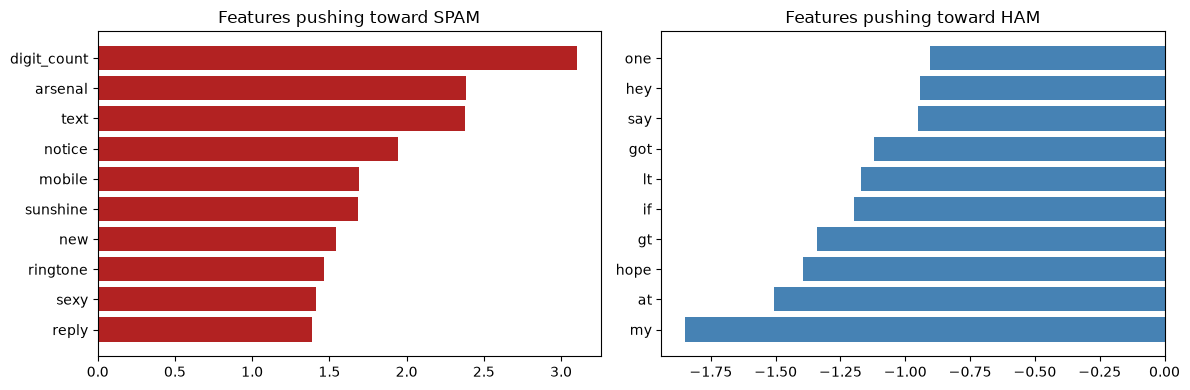

In [21]:
# two bar charts side by side: spam features on the left, ham features on the right
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.barh(top_spam.index, top_spam.values, color="firebrick")
plt.title("Features pushing toward SPAM")

plt.subplot(1, 2, 2)
plt.barh(top_ham.index, top_ham.values, color="steelblue")
plt.title("Features pushing toward HAM")

plt.tight_layout()
plt.show()

In [22]:
# Messages the model got wrong on the testing data
results = X_test[["message"]].copy()
results["actual"] = y_test
results["predicted"] = y_pred

pd.set_option("display.max_colwidth", 120)

# actual = spam but predicted = ham
print("Spam messages that the model missed (false negatives):")
display(results[(results["actual"] == 1) & (results["predicted"] == 0)])

# actual = ham but predicted = spam
print("Normal messages predicted as spam (false positives):")
display(results[(results["actual"] == 0) & (results["predicted"] == 1)])

Spam messages that the model missed (false negatives):


,message,actual,predicted
1830,"FreeMsg Hey U, i just got 1 of these video/pic fones, reply WILD to this txt & ill send U my pics, hurry up Im so bo...",1,0
4499,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo,1,0
2642,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-C...,1,0
3743,ringtoneking 84484,1,0
1813,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!,1,0
3890,"In The Simpsons Movie released in July 2007 name the band that died at the start of the film? A-Green Day, B-Blue Da...",1,0
1415,Bought one ringtone and now getting texts costing 3 pound offering more tones etc,1,0
5064,"Latest News! Police station toilet stolen, cops have nothing to go on!",1,0


Normal messages predicted as spam (false positives):


,message,actual,predicted
568,"I'm tired of arguing with you about this week after week. Do what you want and from now on, i'll do the same.",0,1
3599,"Please protect yourself from e-threats. SIB never asks for sensitive information like Passwords,ATM/SMS PIN thru ema...",0,1
2149,"""Si.como no?!listened2the plaid album-quite gd&the new air1 which is hilarious-also boughtbraindancea comp.ofstuff...",0,1


The words pushing towards spam are mostly promo words like `text`, `notice`, `mobile`, `new`, `ringtone`, `sexy` and `reply`. The ham words are everyday ones like `my`, `at`, `hope`, `if`, `got`, `say` and `hey`. `digit_count` has the biggest coefficient of all (3.1), which matches its high correlation with spam in section 1.5.

A few results are just quirks of this dataset. `lt` and `gt` look like ham words only because the text `&lt;#&gt;` (a placeholder for a number) appears in 197 ham messages and in no spam message. `arsenal` and `sunshine` also get big spam coefficients, but they appear in very few messages (`arsenal` in only 2 spam messages), so the model learned them from almost nothing and they wouldn't help on other data.

Some of the 8 missed spam messages are short or look like normal texts (for example "ringtoneking 84484", a movie quiz question and a news-style joke), and one has scrambled spelling. Among the 3 normal messages flagged as spam are a bank security notice, which sounds like a typical alert, and two casual messages in texting shorthand.

### 1.16 Limitations and Conclusion

**Limitations**

- The data is from around 2011 and is in English. Spam in India today (bank and OTP scams, Hinglish, short links) looks different, so the model would probably do worse there. We didn't test this.
- The test set has only 131 spam messages, so one message changes the recall by about 0.8%.
- We chose the settings (1000 words, `min_df=2`, default `C`) by hand and didn't tune them.
- The model only counts words, so it ignores word order and can be fooled by scrambled spelling.

**Conclusion**

Logistic Regression on word counts plus four numeric features separates spam from ham well: accuracy 98.9%, spam precision 97.6%, spam recall 93.9% and F1-score 0.957. The coefficients are easy to read, which helped us understand the results. The main weak spots are short or unusual spam, a small amount of overfitting, and how old the data is.